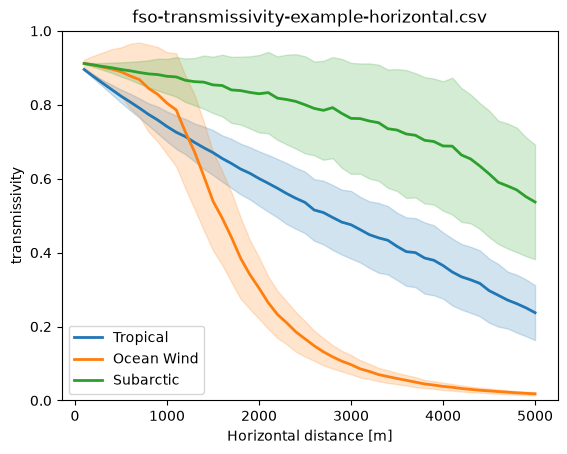

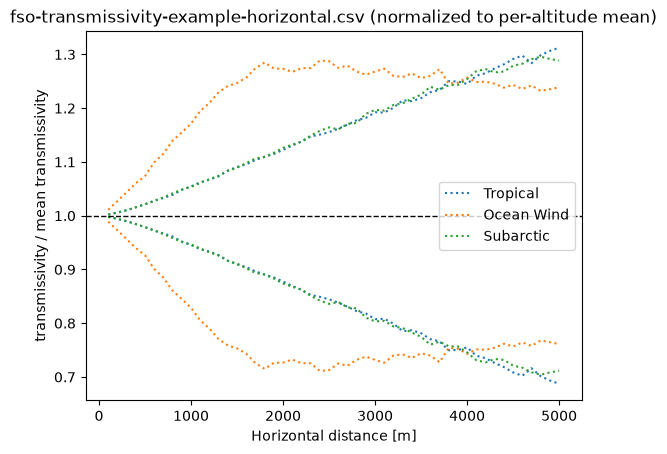

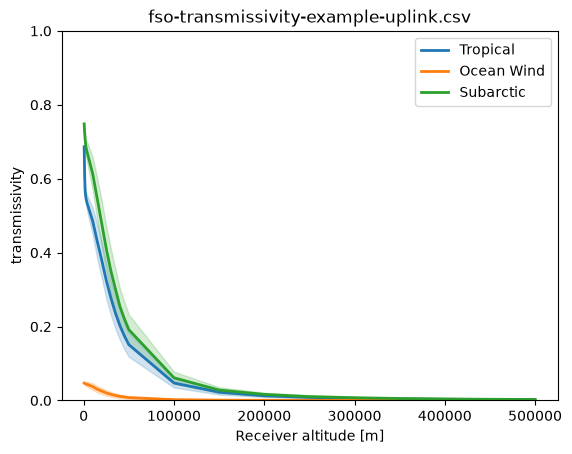

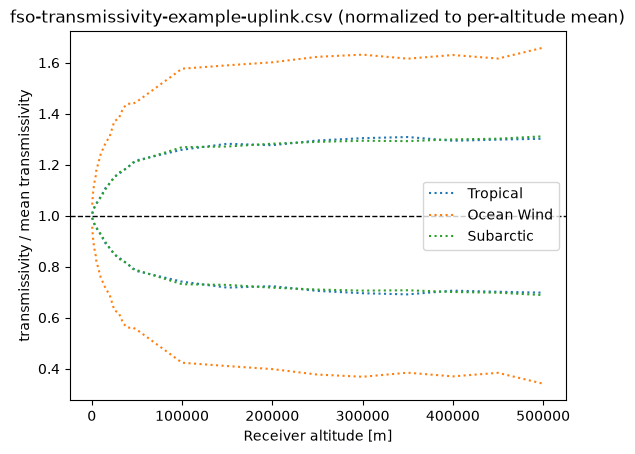

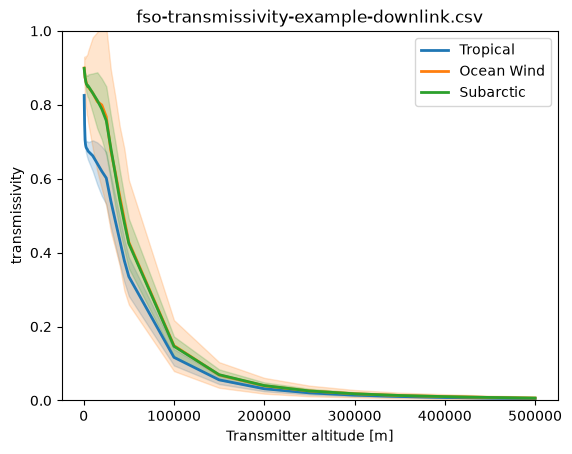

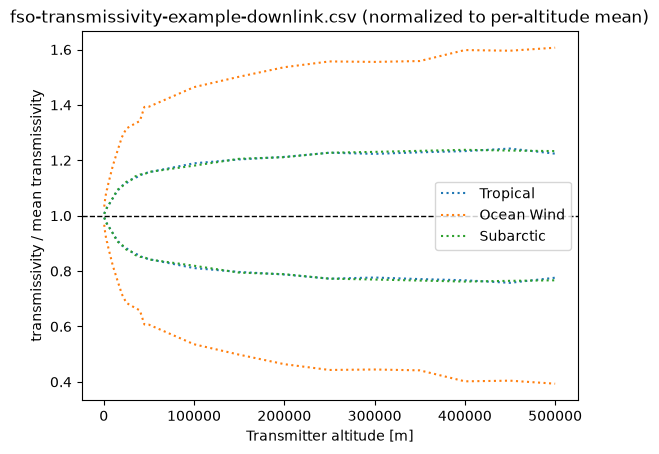

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import glob

for file in glob.glob("qdl_fso_transmissivity_example_*.csv"):
    df = pd.read_csv(file)
    x_col = df.columns[0]
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    # First plot: mean with ±1 std envelope
    plt.figure()
    for i, col in enumerate(df.columns[1:]):
        color = colors[i % len(colors)]
        grouped = df.groupby(x_col)[col]
        avg = grouped.mean()
        std = grouped.std()
        plt.plot(avg.index, avg, linewidth=2, color=color, label=col)
        plt.fill_between(avg.index, avg - std, avg + std, color=color, alpha=0.2)
    plt.ylim(0, 1)
    plt.legend()
    plt.title(file)
    plt.xlabel(x_col)
    plt.ylabel("transmissivity")

    # Normalized plot: only the std envelopes, colored per series
    plt.figure()
    for i, col in enumerate(df.columns[1:]):
        color = colors[i % len(colors)]
        avg_per_row = df.groupby(x_col)[col].transform("mean")
        ratio = df[col] / avg_per_row
        std = ratio.groupby(df[x_col]).std()
        plt.plot(std.index, 1 + std, ":", linewidth=1.5, color=color, label=col)
        plt.plot(std.index, 1 - std, ":", linewidth=1.5, color=color)
    plt.axhline(1, color="black", linewidth=1, linestyle="--")
    plt.legend()
    plt.title(f"{file} (normalized to per-altitude mean)")
    plt.xlabel(x_col)
    plt.ylabel("transmissivity / mean transmissivity")
    plt.show()

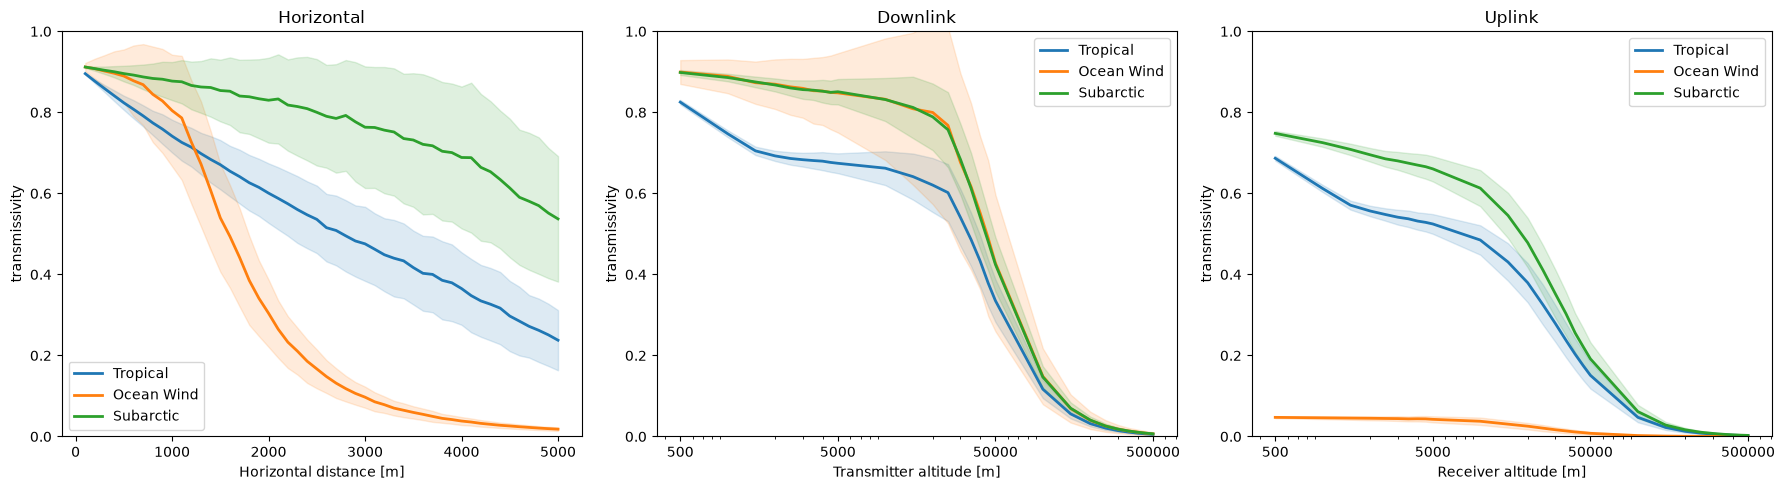

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

files = [
    "qdl_fso_transmissivity_example_horizontal.csv",
    "qdl_fso_transmissivity_example_downlink.csv",
    "qdl_fso_transmissivity_example_uplink.csv",
]

titles = [
    "Horizontal",
    "Downlink",
    "Uplink",
]

log_x = [False, True, True]

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, axes = plt.subplots(1, len(files), figsize=(18, 5), sharey=False)

for i in range(len(files)):
    file = files[i]
    title = titles[i]
    ax = axes[i]
    do_log_scale = log_x[i]
    df = pd.read_csv(file)
    x_col = df.columns[0]

    for j, col in enumerate(df.columns[1:]):
        color = colors[j % len(colors)]
        grouped = df.groupby(x_col)[col]
        avg = grouped.mean()
        std = grouped.std()
        ax.plot(avg.index, avg, linewidth=2, color=color, label=col)
        ax.fill_between(avg.index, avg - std, avg + std, color=color, alpha=0.15)

    ax.set_ylim(0, 1)
    if do_log_scale:
        ax.set_xscale("log")
        ax.set_xticks([500, 5000, 50000, 500000])
        ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel("transmissivity")
    ax.legend()


plt.tight_layout()
plt.show()

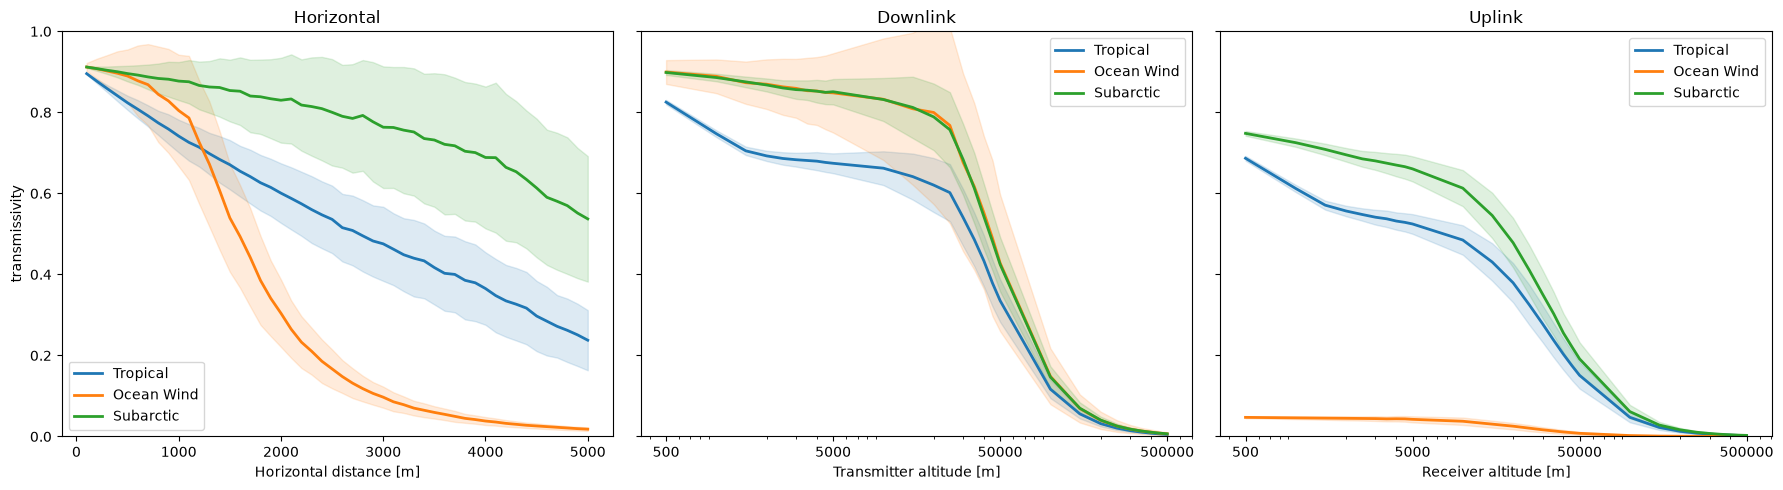

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplot2tikz

files = [
    "qdl_fso_transmissivity_example_horizontal.csv",
    "qdl_fso_transmissivity_example_downlink.csv",
    "qdl_fso_transmissivity_example_uplink.csv",
]

titles = [
    "Horizontal",
    "Downlink",
    "Uplink",
]

log_x = [False, True, True]

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, axes = plt.subplots(1, len(files), figsize=(18, 5), sharey=True)

for i in range(len(files)):
    file = files[i]
    title = titles[i]
    ax = axes[i]
    do_log_scale = log_x[i]
    df = pd.read_csv(file)
    x_col = df.columns[0]

    for j, col in enumerate(df.columns[1:]):
        color = colors[j % len(colors)]
        grouped = df.groupby(x_col)[col]
        avg = grouped.mean()
        std = grouped.std()
        ax.plot(avg.index, avg, linewidth=2, color=color, label=col)
        ax.fill_between(avg.index, avg - std, avg + std, color=color, alpha=0.15)

    ax.set_ylim(0, 1)
    if do_log_scale:
        ax.set_xscale("log")
        ax.set_xticks([500, 5000, 50000, 500000])
        ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.set_title(title)
    ax.set_xlabel(x_col)
    if i == 0:
        ax.set_ylabel("transmissivity")
    # ax.grid(axis="y", linestyle="-", alpha=0.4)   # horizontal grid lines only
    # ax.set_axisbelow(True)                        # grid drawn behind the curves
    ax.legend()

plt.tight_layout()
matplot2tikz.clean_figure()   # optional: drops points outside the axes, shrinks the file
matplot2tikz.save("qdl-fso-transmissivity-example-plots.tex")